# Machine Learning and Neural Networks
## Problem set 1: Regression

Welcome to tutorial #1. This contains a number of problems for you to solve - some involve solving the equations, and some implementing them in code. You can download this notebook to fill in the gaps.



### Concepts

#### 1:

In a simple linear regression model $y = w_0 + w_1x + ϵ$, what is the role of each term:

* $w_0$: The intercept of the model
* $w_1$: The slope of the model
* $ϵ$: The noise or deviation term

#### 2:

Using the following data:

| x | y |
| --- | --- |
| 1 | 2.8 |
| 2 | 5.1 |
| 3 | 6.7 |

Calculate the optimal values of $w_0$ and $w_1$

* $w_0 = 1.950$
* $w_1 = 0.967$

#### 3:

What happens if we add weights to this data?

| x | y | $w_y$ |
| --- | --- | -- |
| 1 | 2.8 | 0.4 |
| 2 | 5.1 | 0.3 |
| 3 | 6.7 | 0.6 |

* $w_0 = 0.967$
* $w_1 = 1.933$

### Code

#### 4:

Using only pure python and numpy, implement a simple linear regression algorithm. Use it to derive $w_0$ and $w_1$ for the values below.

In [4]:
import numpy as np

x = np.array([4.14, 1.88, 2.11, 7.86, 0.23, 3.44, 8.77, 0.83, 3.74, 7.88, 9.88, 2.55, 2.70, 4.51, 8.14, 5.09, 0.14, 6.87, 9.55, 9.59, ])# 0.1, 2.7,
y = np.array([5.10, 2.04, 1.50, 8.52, 1.65, 3.79, 9.48, 3.26, 5.76, 8.90, 13.45, 3.95, 3.88, 4.97, 8.43, 7.00, 0.66, 7.56, 11.47, 9.20, ])

# Enter your solution here:
def linear_regression(x, y):
  """
  Performs linear regression using the ordinary least squares method.

  Args:
    x: A numpy array of independent variable values.
    y: A numpy array of dependent variable values.

  Returns:
    A tuple containing the intercept (w0) and slope (w1) of the regression line.
  """
  n = len(x)
  x_mean = np.mean(x)
  y_mean = np.mean(y)

  numerator = np.sum((x - x_mean) * (y - y_mean))
  denominator = np.sum((x - x_mean)**2)

  w1 = numerator / denominator
  w0 = y_mean - w1 * x_mean

  return w0, w1

# Example usage with provided data
w0, w1 = linear_regression(x, y)

print(f"w0 (intercept): {w0:.2f}")
print(f"w1 (slope): {w1:.2f}")

w0 (intercept): 0.89
w1 (slope): 1.03


In [5]:
# Solution:

import numpy as np

def linear_regression(x, y):
  """
  Performs linear regression using the ordinary least squares method.

  Args:
    x: A numpy array of independent variable values.
    y: A numpy array of dependent variable values.

  Returns:
    A tuple containing the intercept (w0) and slope (w1) of the regression line.
  """
  n = len(x)
  x_mean = np.mean(x)
  y_mean = np.mean(y)

  numerator = np.sum((x - x_mean) * (y - y_mean))
  denominator = np.sum((x - x_mean)**2)

  w1 = numerator / denominator
  w0 = y_mean - w1 * x_mean

  return w0, w1

# You could also implement this as:

def linear_regression(x, y):
  w1 = (np.sum(x*y) - 1/x.shape[0] * np.sum(x) * np.sum(y))/(np.sum(x**2) - 1/x.shape[0] * np.sum(x)**2)
  w0 = 1/x.shape[0] * np.sum(y - y.mean()) - w1 * 1/x.shape[0] * np.sum(x)
  return w0, w1

# Example usage with provided data
w0, w1 = linear_regression(x, y)

print(f"w0 (intercept): {w0:.2f}")
print(f"w1 (slope): {w1:.2f}")

# Which can also be compared with SKLearn
lrmodel = LinearRegression().fit(x.reshape(-1, 1), y)
lrminter=lrmodel.intercept_
lrmcoefs=lrmodel.coef_
print(f"w0 (intercept): {lrminter:.2f}")
print(f"w1 (slope): {lrmcoefs[0]:.2f}")



# Code which generated the data was:

# import numpy as np

# # Generate random x values
# x = np.random.rand(20) * 10

# # Generate y values from a low-order polynomial with weak non-linearity
# y = 2 + 0.5 * x + 0.05 * x**2

# # Add some noise to y
# noise = np.random.randn(20)
# y = y + noise


# print("x = np.array([", end="")
# for i in range(len(x)):
#   print(f"{x[i]:.2f}, ", end="")
# print("])")

# print("y = np.array([", end="")
# for i in range(len(y)):
#   print(f"{y[i]:.2f}, ", end="")
# print("])")

w0 (intercept): -5.14
w1 (slope): 1.03
w0 (intercept): 0.89
w1 (slope): 1.03


#### 5:

The file `inputdata-5.csv` contains data relating sales (gross revenue) at a medium-sized company to advertising spend (all in thousands of GBP per month, adjusted for inflation). Each line corresponds to one month. The left and middle columns in this file show the amount spent on advertising, the right column shows the level of sales (revenue).

Split the data into training and test data, and use linear regression to create models of the form:

$$S=u+k_1 A_1 $$
$$S = u + k_2 A_2 $$
and
$$S = u+ k_1 A_1 + k_2 A_2$$
where $S$ is the revenue, $A_1$ and $A_2$ are the amounts spent on online and TV advertising, respectively.

Then evaluate the each model using the test set. How effective is each model, and what else could you do to improve?

Comment on what is happening in each case, and why any of them perform better or worse than others.



Mean squared error: 128.76
Mean squared error: 517.39
Mean squared error: 35.86


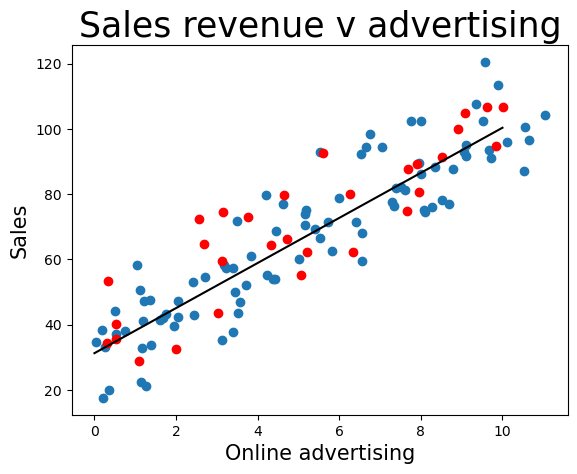

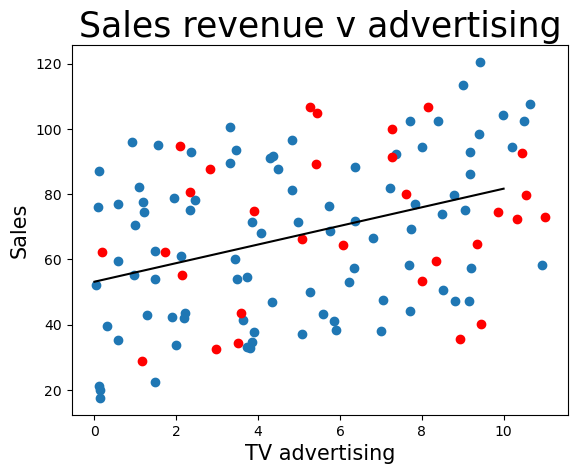

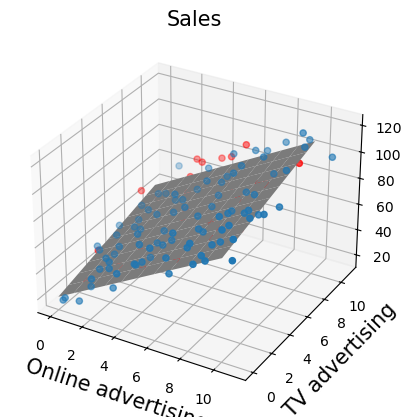

In [6]:
# Enter your solution here:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# read from file and split into three 1d arrays
mydata = np.genfromtxt('inputdata-5.csv', delimiter=',', skip_header=1)
aon=mydata[:,0]  # 1st column, online ads
atv=mydata[:,1]  # 2nd column, tv ads
sal=mydata[:,2]  # 3rd column, sales

# shuffle the arrays
indx=np.arange(aon.size)
np.random.shuffle(indx)
saon=aon[indx]
satv=atv[indx]
ssal=sal[indx]

# split into training and testing data
taon=saon[0:90]  # training data
tatv=satv[0:90]
tsal=ssal[0:90]
caon=saon[91:]  # test data
catv=satv[91:]
csal=ssal[91:]

# uniform arrays for plotting in respect of x and y
xaxi=np.arange(11)
yaxi=np.arange(11)

# Model 1 Sales v Online advertising
# get the fit
x = taon.reshape((-1, 1))
y=tsal
lrmodel = LinearRegression().fit(x, y)

# get a and b
lrminter=lrmodel.intercept_
lrmcoefs=lrmodel.coef_

# plot data and fit
plt.figure(1)
plt.scatter(taon,tsal)
plt.scatter(caon,csal, c='red')
plt.plot(xaxi, lrminter+lrmcoefs*xaxi, color='black')
plt.title('Sales revenue v advertising', fontsize=25)
plt.ylabel('Sales', fontsize=15)
plt.xlabel('Online advertising', fontsize=15)

# predict some values and use testing data to calculate the MSE
y_pred=lrminter+lrmcoefs*caon
print(f"Mean squared error: {mean_squared_error(csal, y_pred):.2f}")


# Model 2 Sales v TV advertising, same as in model 1
x = tatv.reshape((-1, 1))
y=tsal
lrmodel = LinearRegression().fit(x, y)
lrminter=lrmodel.intercept_
lrmcoefs=lrmodel.coef_
plt.figure(2)
plt.scatter(tatv,tsal)
plt.scatter(catv,csal, c='red')
plt.plot(xaxi, lrminter+lrmcoefs*xaxi, color='black')
plt.title('Sales revenue v advertising', fontsize=25)
plt.ylabel('Sales', fontsize=15)
plt.xlabel('TV advertising', fontsize=15)

# predict some values and use testing data to calculate the MSE
y_pred=lrminter+lrmcoefs*catv
print(f"Mean squared error: {mean_squared_error(csal, y_pred):.2f}")


# Model 3 Sales v TV advertising
# x now contains two independent (feature) variables
x = np.vstack((taon,tatv)).T
y=tsal

# fit the data
lrmodel = LinearRegression().fit(x, y)

# extract a, b, c
lrminter=lrmodel.intercept_
lrmcoefs=lrmodel.coef_

# plot data and fit
fig3=plt.figure(3)
ax = fig3.add_subplot(projection='3d')
ax.scatter(taon,tatv,tsal)
ax.scatter(caon,catv,csal, color='red')
plt.xlabel('Online advertising', fontsize=15)
plt.ylabel('TV advertising', fontsize=15)
plt.title('Sales', fontsize=15)

# create mesh for surface plot
xx, yy = np.meshgrid(xaxi, yaxi)
zz=lrminter+lrmcoefs[0]*xx+lrmcoefs[1]*yy
ax.plot_surface(xx, yy, zz, color='grey')

# predict some values and use testing data to calculate the MSE
y_pred=lrminter+lrmcoefs[0]*caon+lrmcoefs[1]*catv
print(f"Mean squared error: {mean_squared_error(csal, y_pred):.2f}")

import pandas as pd
df = pd.DataFrame({'OnlineAdvertising': aon, 'TVAdvertising': atv, 'Revenue': sal})
df.to_csv('inputdata-5.csv', index=False)

### Model selection

#### 6.

The file `inputdata-week1.csv` contains a second dataset. The data has 6 columns - 5 independent variables and a dependent variable. Combine the two techniques we discussed in the first lecture, regression and model selection, to determine which independent variables are significant and find the model which best represents the relationship between the independent and dependent variables.

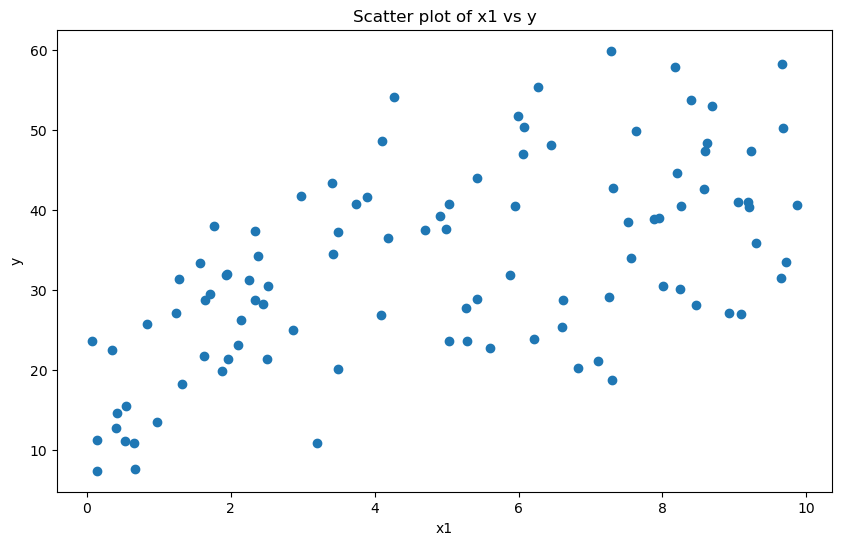

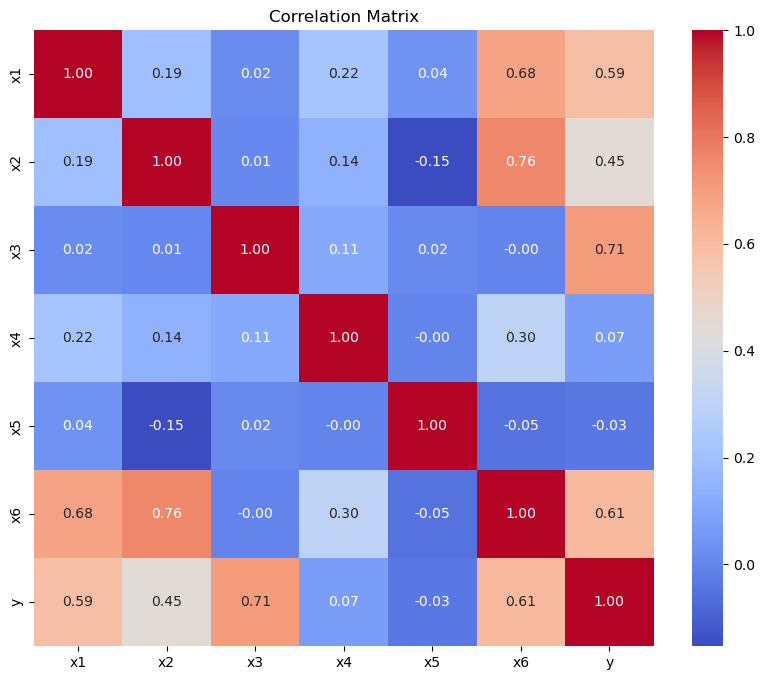

In [7]:
# Code to generate data for inputdata-6.csv:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Generate synthetic data for multiple regression
num_samples = 100
x1 = np.random.rand(num_samples) * 10
x2 = np.random.rand(num_samples) * 5
x3 = np.random.rand(num_samples) * 20
x4 = np.random.rand(num_samples) * 15
x5 = np.random.rand(num_samples) * 8  # This variable will not be significant

# Introduce a cross-term that is significant
x6 = x1 * x2

# Generate dependent variable with noise
y = 5 + 2 * x1 + 3 * x2 + 1.5 * x3 - 0.5 * x4 + 0.1 * x6 + np.random.randn(num_samples) * 2

# Create a Pandas DataFrame for easier handling and plotting
data = pd.DataFrame({'x1': x1, 'x2': x2, 'x3': x3, 'x4': x4, 'x5': x5, 'x6': x6, 'y': y})

# Plot the data
# You can customize this to plot different variables against y
plt.figure(figsize=(10, 6))
plt.scatter(x1, y)
plt.xlabel('x1')
plt.ylabel('y')
plt.title('Scatter plot of x1 vs y')
plt.show()

# Calculate and plot the correlation matrix
correlation_matrix = data.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix')
plt.show()

# Save the data to a file
data.to_csv('synthetic_multiple_regression_data.csv', index=False)

# Now we want to save the data in the format the students will actually use: only x1 - x5 and y should be included:
data_out = data[['x1', 'x2', 'x3', 'x4', 'x5', 'y']]
data_out.to_csv('inputdata-6.csv', index=False)


In [8]:
#Enter your solution here:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Load the data from the CSV file
data = pd.read_csv('inputdata-6.csv')

# Separate features (X) and target variable (y)
X = data.drop('y', axis=1)
y = data['y']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create a dictionary to store the results for each model
results = {}

# iterate over variables combinations:
# Iterate through all possible combinations of features
for i in range(1, 1 << X.shape[1]):  # Iterate through all possible subsets of features

  feature_indices = [j for j in range(X.shape[1]) if (i >> j) & 1]
  features = X.columns[feature_indices]


  # Create a linear regression model with the selected features
  model = LinearRegression()
  model.fit(X_train[features], y_train)

  # Predict on the test set
  y_pred = model.predict(X_test[features])

  # Calculate the test MSE
  mse = mean_squared_error(y_test, y_pred)
  print(f"Trying model {i} using features: {features} --  mse = {mse:.2f}")

  # Store the results
  results[tuple(features)] = mse

  # and now the potential cross terms:
  if len(features) > 1:
    for j in range(len(features)):
        for k in range(j+1, len(features)):

            interaction_features = [features[j], features[k]]
            X_int = X_train[features].copy()
            X_int[f"{features[j]} * {features[k]}"] = X[features[j]] * X[features[k]]
            X_int.head()
            X_int_test = X_test[features].copy()
            X_int_test[f"{features[j]} * {features[k]}"] = X_test[features[j]] * X_test[features[k]]
            X_int_test.head()
            model = LinearRegression()
            model.fit(X_int, y_train)

            # Predict on the test set
            y_pred = model.predict(X_int_test)

            # Calculate the test MSE
            mse = mean_squared_error(y_test, y_pred)

            print(f"Trying interaction term: {features[j]} * {features[k]} -- mse = {mse:.2f}")

            new_features = list(features) + [f"{features[j]} * {features[k]}"]

            # store the results:
            results[tuple(new_features)] = mse

# Find the model with the lowest test MSE
best_model = min(results, key=results.get)
lowest_mse = results[best_model]

print(f"The best model is: {best_model}")
print(f"The lowest test MSE is: {lowest_mse}")


Trying model 1 using features: Index(['x1'], dtype='object') --  mse = 89.14
Trying model 2 using features: Index(['x2'], dtype='object') --  mse = 119.43
Trying model 3 using features: Index(['x1', 'x2'], dtype='object') --  mse = 81.86
Trying interaction term: x1 * x2 -- mse = 85.55
Trying model 4 using features: Index(['x3'], dtype='object') --  mse = 67.83
Trying model 5 using features: Index(['x1', 'x3'], dtype='object') --  mse = 22.17
Trying interaction term: x1 * x3 -- mse = 21.59
Trying model 6 using features: Index(['x2', 'x3'], dtype='object') --  mse = 44.64
Trying interaction term: x2 * x3 -- mse = 45.45
Trying model 7 using features: Index(['x1', 'x2', 'x3'], dtype='object') --  mse = 5.66
Trying interaction term: x1 * x2 -- mse = 5.60
Trying interaction term: x1 * x3 -- mse = 6.20
Trying interaction term: x2 * x3 -- mse = 5.78
Trying model 8 using features: Index(['x4'], dtype='object') --  mse = 131.41
Trying model 9 using features: Index(['x1', 'x4'], dtype='object') -